In [2]:
import sys
import os
import pandas as pd
import duckdb
sys.path.append(os.path.abspath('../src'))
import visualizations as vis
df_logistics = pd.read_parquet('../dataset/processed/mart_logistics_experience.parquet')
df_intent = pd.read_parquet('../dataset/processed/mart_impulse_penalty.parquet')

### 1. Returns vs. fulfilment time: binned comparison (descriptive)

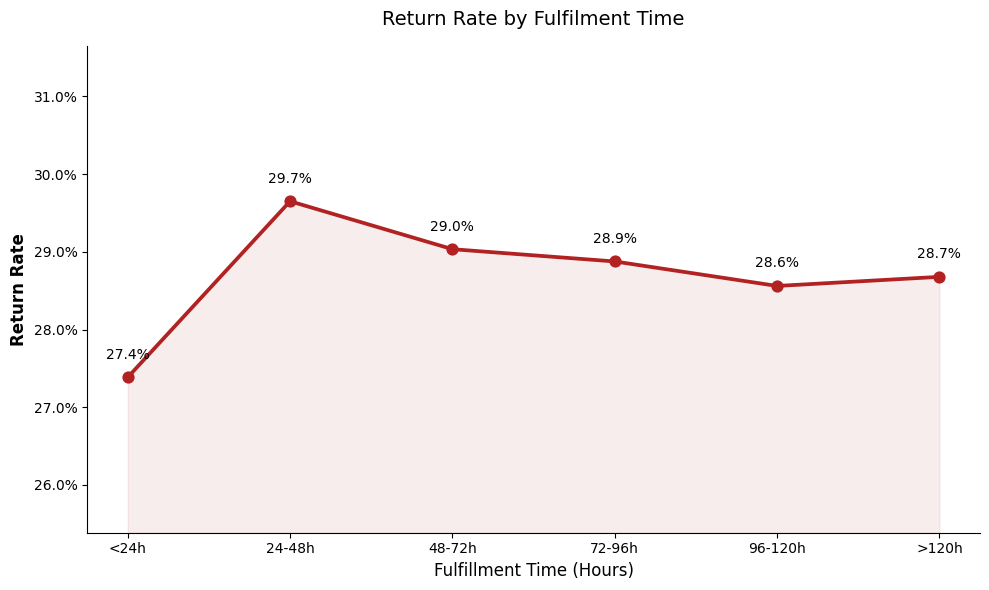

In [3]:
vis.plot_logistics_trend(df_logistics)

**Question:** Are longer fulfilment times associated with higher return rates?

**Observation:** In `mart_logistics_experience` (delivered orders), the order-level return rate stays within about 28–30% across fulfilment-time bins, from under 24 hours to over 120 hours.

**Interpretation:** In this dataset, fulfilment time is not associated with a higher return rate. This is a descriptive comparison of group means with no significance test and no adjustment for product mix, order size or customer attributes, and the data is synthetic. It gives no reason to expect that faster shipping alone would reduce returns, but it cannot rule out an effect.

**Next step:** Look at multi-warehouse split shipments (`total_dc > 1`) and add confidence intervals and bin sizes to the chart.

### 2. Returns vs. fulfilment time: fitted return probability (descriptive)

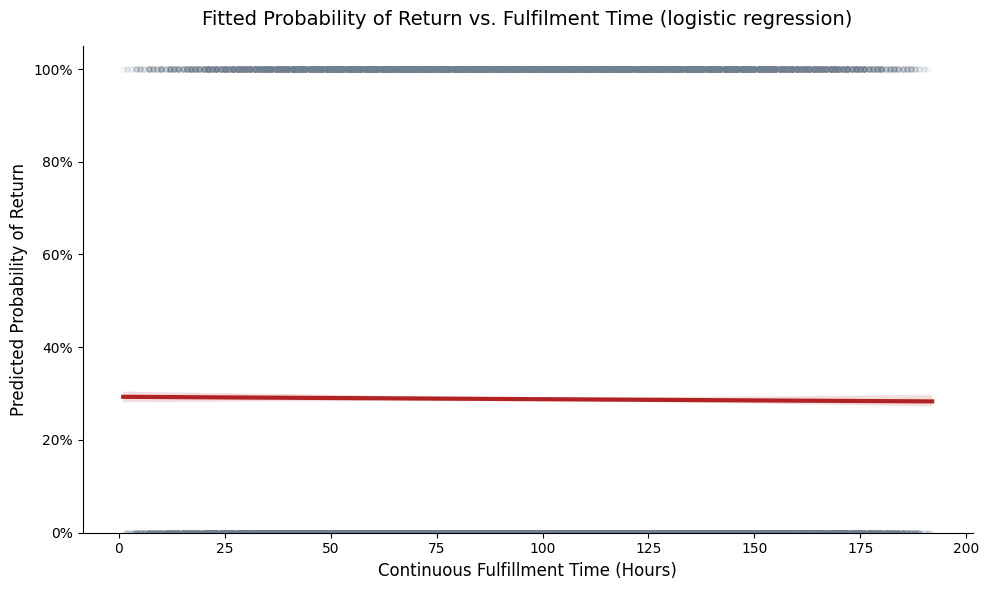

In [4]:
vis.plot_logistic_return_probability(df_logistics)

**What the chart shows:** A logistic regression of the return flag on fulfilment time (the only predictor), with a bootstrapped 95% band. The fitted curve is almost flat: about 29% at short fulfilment times, drifting down to about 28% at around 190 hours.

**Interpretation:** This agrees with the binned comparison in section 1: in this dataset, fulfilment time carries little information about whether an order is returned. If anything, the curve tilts very slightly downward (about one percentage point across the observed range), which is the opposite of the original hypothesis; no significance test was run and the change is small. A single logistic curve has a smooth, one-directional shape, so the binned comparison is the better check for a threshold effect (for example, a jump after 72 hours). The same limitations apply: one predictor, no adjustment for other factors, synthetic data.

### 3. Impulse Penalty: return rate by session intent

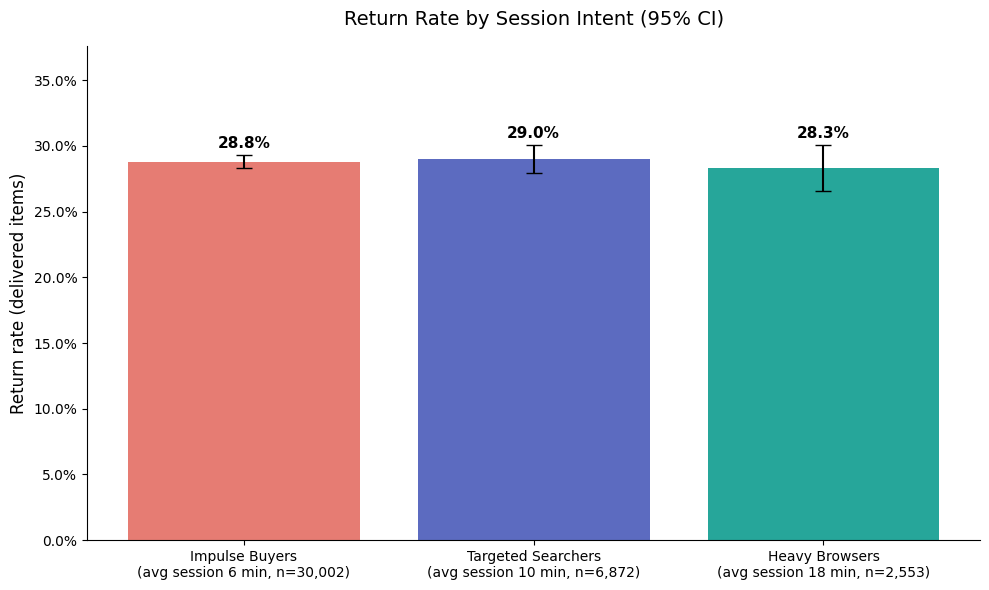

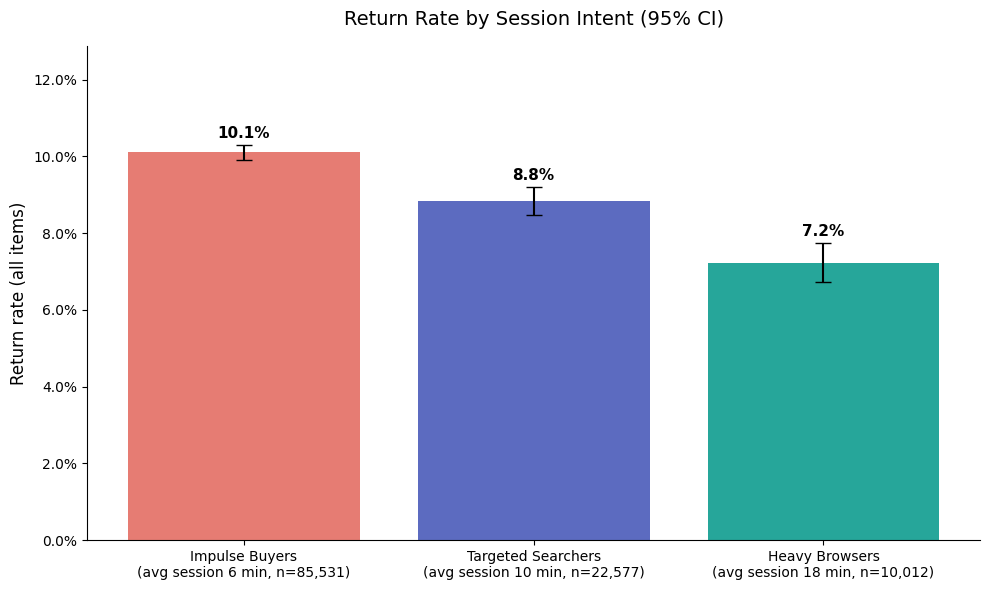

In [5]:
vis.plot_impulse_penalty(df_intent)                                     # delivered items
vis.plot_impulse_penalty(df_intent, rate_col='return_rate_all_items')  # all items

**Session intent vs. returns: no difference among delivered items.** 
- Purchase sessions are matched to order items by user and a window from 1 hour before to 4 hours after the purchase event; this matches 118,120 of the 145,577 order items in the cleaned data (81.1%) and 102,847 of 181,466 purchase sessions (56.7%). Among delivered items, the only ones that can be returned, the return rate is almost identical across segments: 28.8% for Impulse Buyers (n = 30,002), 29.0% for Targeted Searchers (n = 6,872) and 28.3% for Heavy Browsers (n = 2,553), with overlapping approximate 95% intervals. When all items are counted the rates differ (10.1%, 8.8% and 7.2%), but only because a smaller share of items reached delivery in the browsing-heavy segments (35.1%, 30.4% and 25.5%), not because delivered items were returned less often. Sessions in the Heavy Browsers segment also contain far more items (2.7 per session vs 1.0 for Impulse Buyers), so the segments largely reflect basket size. This is an observational comparison with no adjustment for product mix, and it does not show that browsing affects returns (see the README, Limitation 5).

### Appendix: session-to-order matching diagnostics

`mart_impulse_penalty` links purchase sessions to order items by user and a window from 1 hour before to 4 hours after the purchase event, keeping the closest session per item. This appendix uses a wider ±24-hour window to show how the time gaps between purchase events and orders are distributed, which is why that window was chosen. It is a diagnostic only and does not change the mart (see Limitation 5 in the README).

The mart matches 118,120 items because it picks the closest session within its own window; the 118,052 here picks the closest session within ±24 hours first and then counts the items inside the window.

In [6]:
MATCH_CTES = """
WITH session_aggregated AS (
    SELECT session_id, MAX(user_id) AS user_id,
           MAX(CASE WHEN event_type = 'purchase' THEN 1 ELSE 0 END) AS is_purchase_session,
           MAX(CASE WHEN event_type = 'purchase' THEN event_created_at ELSE NULL END) AS purchase_event_time
    FROM '../dataset/processed/Frontend_Traffic_OBT.parquet'
    GROUP BY session_id
),
intent_tagged AS (
    SELECT session_id, user_id, purchase_event_time FROM session_aggregated WHERE is_purchase_session = 1
),
matched AS (
    SELECT i.session_id, o.order_items_id,
           DATE_DIFF('second', i.purchase_event_time, o.order_created_at)      AS signed_gap_sec,
           ABS(DATE_DIFF('second', i.purchase_event_time, o.order_created_at)) AS gap_sec
    FROM intent_tagged i
    JOIN '../dataset/processed/Backend_Sales_OBT.parquet' o
      ON i.user_id = o.user_id
     AND o.order_created_at BETWEEN i.purchase_event_time - INTERVAL 24 HOUR
                                AND i.purchase_event_time + INTERVAL 24 HOUR
    QUALIFY ROW_NUMBER() OVER (
        PARTITION BY o.order_items_id
        ORDER BY ABS(DATE_DIFF('second', i.purchase_event_time, o.order_created_at))
    ) = 1
)
"""

duckdb.sql(MATCH_CTES + """
SELECT COUNT(*) FILTER (WHERE gap_sec <= 1800)  AS items_within_30min,
       COUNT(*) FILTER (WHERE gap_sec <= 7200)  AS items_within_2h,
       COUNT(*) FILTER (WHERE gap_sec <= 21600) AS items_within_6h,
       COUNT(*)                                 AS items_within_24h,
       COUNT(*) FILTER (WHERE signed_gap_sec BETWEEN -3600 AND 14400) AS items_minus1h_to_plus4h
FROM matched
""").df()

,items_within_30min,items_within_2h,items_within_6h,items_within_24h,items_minus1h_to_plus4h
0,19980,65021,118204,134068,118052


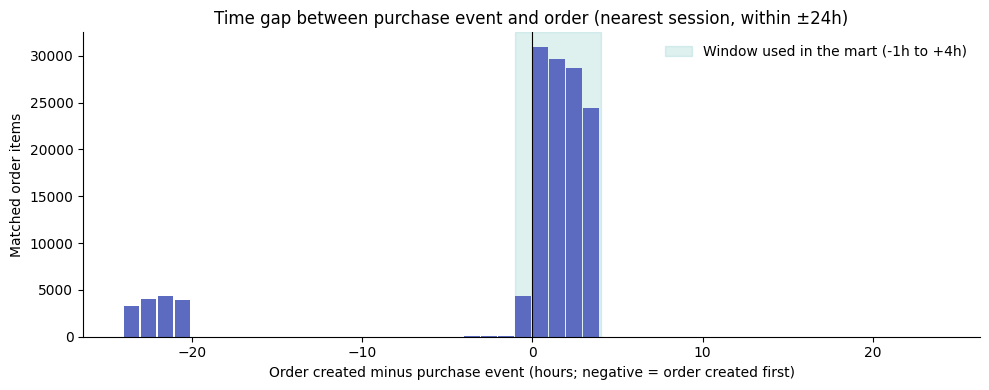

In [7]:
gaps = duckdb.sql(MATCH_CTES + """
SELECT CAST(FLOOR(signed_gap_sec / 3600.0) AS INTEGER) AS gap_hour, COUNT(*) AS items
FROM matched
GROUP BY 1
ORDER BY 1
""").df()

vis.plot_match_gap_hist(gaps)